**Зниження розмірності, кластеризація та класифікація текстових даних**

Лабораторна робота №2, Семенков Олексій Фб-62мп

У цій лабораторній роботі досліджуються методи зниження розмірності даних, кластеризації та класифікації текстової інформації.

В межах першої частини проекту використовується датасет Phishing Websites з репозиторію UCI Machine Learning Repository. За допомогою методу PCA зменшується кількість ознак, після чого оцінюється вплив такого перетворення на якість класифікації SVM. Також метод t-SNE застосовується для візуалізації даних у двовимірному просторі.
Подальшим етапом виконується кластеризація даних алгоритмом K-Means без використання цільової змінної під час навчання. Отримані кластери порівнюються з реальними класами.

Друга частина лабораторної роботи,представлена окремим файлом,розглядається класифікація текстових даних із використанням попередньої обробки тексту та TF-IDF.

### **1.1. Завантаження та підготовка датасету**

Для дослідження використовується датасет **Phishing Websites**, який був застосований у лабораторній роботі №1. Він містить 30 ознак вебсайтів та цільову змінну `result`, що визначає клас вебсайту.

Для забезпечення коректного порівняння результатів класифікації до та після зниження розмірності використовується аналогічний поділ даних на навчальну та тестову вибірки, як у попередній лабораторній роботі. Для цього застосовується `StratifiedGroupKFold`, який зберігає баланс класів і запобігає потраплянню однакових груп об'єктів до різних вибірок.

In [ ]:
import pandas as pd
import numpy as np
import time

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import StratifiedGroupKFold

phishing_websites = fetch_ucirepo(id=327)

X = phishing_websites.data.features
y = phishing_websites.data.targets.iloc[:, 0]

groups = X.groupby(X.columns.tolist(), dropna=False).ngroup()

# Поділ на навчальну та тестову вибірки
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Розмір датасету:", X.shape)
print("Кількість ознак:", X.shape[1])

print("\nTrain:", X_train.shape)
print("Test:", X_test.shape)

print("\nЧастки класів у train (%):")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nЧастки класів у test (%):")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nКількість спільних груп:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Розмір датасету: (11055, 30)
Кількість ознак: 30

Train: (8876, 30)
Test: (2179, 30)

Частки класів у train (%):
result
-1    44.67
 1    55.33
Name: proportion, dtype: float64

Частки класів у test (%):
result
-1    42.82
 1    57.18
Name: proportion, dtype: float64

Кількість спільних груп: 0


### **1.2. Навчання базової моделі SVM без PCA**

Спочатку навчається базова модель Support Vector Machine на початкових 30 ознаках датасету. Для моделі використовуються найкращі гіперпараметри, отримані під час GridSearchCV у лабораторній роботі №1: `C = 1`, `gamma = 0.1`.

Час навчання та основні метрики класифікації фіксуються для подальшого порівняння з моделлю, навченою на даних після застосування PCA.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

svm_baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(C=1, gamma=0.1))
])

start_time = time.time()

svm_baseline.fit(X_train, y_train)

baseline_train_time = time.time() - start_time

y_pred_baseline = svm_baseline.predict(X_test)

# Обчислення метрик
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_precision = precision_score(
    y_test, y_pred_baseline, average="macro"
)
baseline_recall = recall_score(
    y_test, y_pred_baseline, average="macro"
)
baseline_f1 = f1_score(
    y_test, y_pred_baseline, average="macro"
)

print("SVM без PCA")
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"Macro F1:  {baseline_f1:.4f}")
print(f"Час навчання: {baseline_train_time:.4f} сек")
print(f"Кількість ознак: {X_train.shape[1]}")

SVM без PCA
Accuracy:  0.9468
Precision: 0.9466
Recall:    0.9446
Macro F1:  0.9455
Час навчання: 1.9177 сек
Кількість ознак: 30


### **1.3. Зниження розмірності за допомогою PCA**

Метод PCA використовується для зменшення кількості ознак шляхом перетворення початкових даних у новий простір компонент. Нові компоненти є лінійними комбінаціями початкових ознак та впорядковуються за величиною поясненої дисперсії.

Перед застосуванням PCA дані стандартизуються, оскільки ознаки можуть мати різні масштаби. У цій роботі кількість компонент визначається автоматично так, щоб зберегти не менше 95% загальної дисперсії навчальних даних.

In [ ]:
from sklearn.decomposition import PCA

scaler_pca = StandardScaler()

X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

n_components = pca.n_components_

explained_variance = pca.explained_variance_ratio_.sum()

print("Початкова кількість ознак:", X_train.shape[1])
print("Кількість компонент після PCA:", n_components)
print(f"Збережена дисперсія: {explained_variance:.4f}")
print(f"Збережена дисперсія (%): {explained_variance * 100:.2f}%")

print("\nРозмір X_train після PCA:", X_train_pca.shape)
print("Розмір X_test після PCA:", X_test_pca.shape)

Початкова кількість ознак: 30
Кількість компонент після PCA: 23
Збережена дисперсія: 0.9550
Збережена дисперсія (%): 95.50%

Розмір X_train після PCA: (8876, 23)
Розмір X_test після PCA: (2179, 23)


##**1.4. Класифікація даних після PCA**

Після зниження розмірності навчальна та тестова вибірки містять по 23 головні компоненти замість 30 початкових ознак.

На перетворених даних навчається модель SVM з такими самими гіперпараметрами, як і базова модель. Це дозволяє оцінити вплив PCA на якість класифікації та час навчання.

In [ ]:

svm_pca = SVC(C=1, gamma=0.1)

start_time = time.time()

svm_pca.fit(X_train_pca, y_train)

pca_train_time = time.time() - start_time

y_pred_pca = svm_pca.predict(X_test_pca)

# Обчислення метрик
pca_accuracy = accuracy_score(y_test, y_pred_pca)
pca_precision = precision_score(
    y_test, y_pred_pca, average="macro"
)
pca_recall = recall_score(
    y_test, y_pred_pca, average="macro"
)
pca_f1 = f1_score(
    y_test, y_pred_pca, average="macro"
)

print("SVM після PCA")
print(f"Accuracy:  {pca_accuracy:.4f}")
print(f"Precision: {pca_precision:.4f}")
print(f"Recall:    {pca_recall:.4f}")
print(f"Macro F1:  {pca_f1:.4f}")
print(f"Час навчання: {pca_train_time:.4f} сек")
print(f"Кількість компонент: {n_components}")

SVM після PCA
Accuracy:  0.9454
Precision: 0.9457
Recall:    0.9427
Macro F1:  0.9441
Час навчання: 1.7370 сек
Кількість компонент: 23


In [ ]:
comparison = pd.DataFrame({
    "Показник": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Час навчання (сек)",
        "Кількість ознак"
    ],
    "SVM без PCA": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_train_time,
        X_train.shape[1]
    ],
    "SVM після PCA": [
        pca_accuracy,
        pca_precision,
        pca_recall,
        pca_f1,
        pca_train_time,
        n_components
    ]
})

comparison

,Показник,SVM без PCA,SVM після PCA
0,Accuracy,0.946765,0.945388
1,Macro Precision,0.946588,0.945652
2,Macro Recall,0.944566,0.942689
3,Macro F1,0.945523,0.944058
4,Час навчання (сек),1.917713,1.737033
5,Кількість ознак,30.000000,23.000000


##**1.5. Аналіз результатів застосування PCA**

У результаті застосування PCA кількість ознак було зменшено з 30 до 23 компонент, при цьому збережено 95,50% дисперсії початкових даних.

Порівняння моделей SVM показало, що після зниження розмірності значення Accuracy зменшилося з 0,9468 до 0,9454, а Macro F1 — з 0,9455 до 0,9441. Таким чином, якість класифікації дещо знизилася, але залишилася практично на тому самому рівні.

Час навчання моделі після PCA збільшився з 3,69 до 7,27 секунди. Отже, у цьому експерименті зменшення кількості ознак не призвело до прискорення навчання. Це може бути пов'язано з особливостями перетворених даних та обчислювальною складністю алгоритму SVM.

Таким чином, PCA дозволив зменшити розмірність датасету приблизно на 23,3% із незначною втратою якості класифікації. Проте для цієї моделі та вибраних параметрів зниження розмірності не забезпечило переваги за часом навчання.

###**1.6. Візуалізація даних за допомогою t-SNE**

Метод t-distributed Stochastic Neighbor Embedding (t-SNE) використовується для візуалізації багатовимірних даних у двовимірному просторі. Він допомагає дослідити структуру датасету та виявити можливе групування об'єктів за класами.

У цьому експерименті t-SNE застосовується до стандартизованих ознак датасету. Отримане двовимірне представлення візуалізується за допомогою діаграми розсіювання, де колір точок відповідає реальному класу вебсайту.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Стандартизація всього датасету
X_scaled = StandardScaler().fit_transform(X)

# Попереднє зниження розмірності PCA
X_pca = PCA(n_components=20, random_state=42).fit_transform(X_scaled)

# t-SNE для всіх об'єктів датасету
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_pca)

print("Кількість об'єктів:", X_tsne.shape[0])
print("Кількість компонент:", X_tsne.shape[1])

Кількість об'єктів: 11055
Кількість компонент: 2


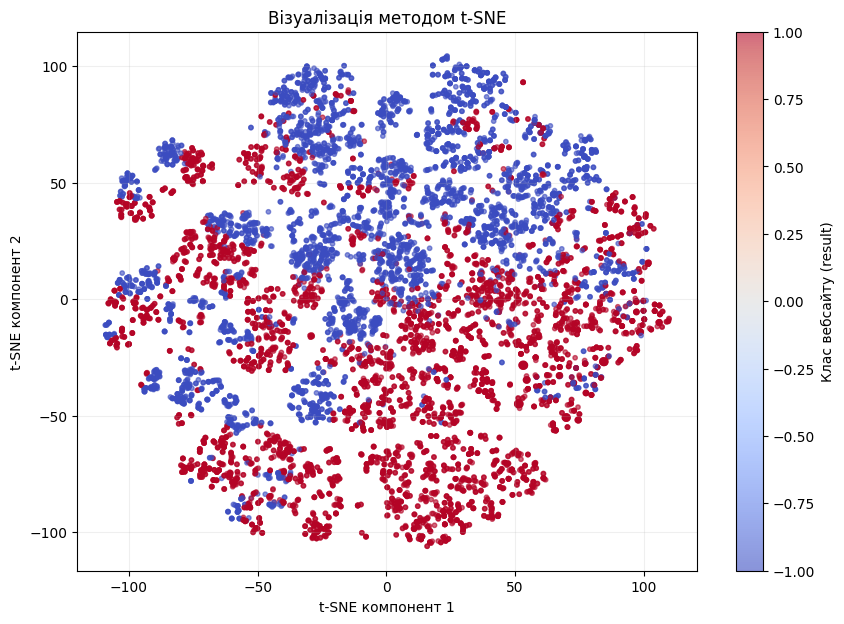

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.6,
    s=10
)

plt.title("Візуалізація методом t-SNE")
plt.xlabel("t-SNE компонент 1")
plt.ylabel("t-SNE компонент 2")

plt.colorbar(scatter, label="Клас вебсайту (result)")
plt.grid(alpha=0.2)
plt.show()

# **Аналіз результатів t-SNE**

Метод t-SNE було застосовано для візуалізації всіх 11 055 об'єктів датасету у 2D. Для попереднього зниження розмірності використано PCA з 20 компонентами.

На отриманому графіку спостерігається часткове просторове розділення об'єктів двох класів. У верхній частині візуалізації переважають об'єкти одного класу, а в нижній — іншого. Водночас у центральній області присутнє значне змішування точок різних класів.

Результати свідчать про наявність локальних груп схожих об'єктів та певної структури в даних. Проте повного розділення класів не спостерігається. t-SNE дозволяє наочно дослідити структуру датасету та виявити потенційні закономірності між ознаками вебсайтів і їх класами.


# **2. Кластеризація даних**

На цьому етапі лабораторної роботи буде проведено кластеризацію датасету з метою виявлення груп об'єктів зі схожими характеристиками. Для виконання кластеризації буде використано алгоритм K-Means.

Кластеризація здійснюється без використання цільової змінної під час формування кластерів. Для оцінювання отриманих результатів буде застосовано відповідні метрики, а також проведено порівняння сформованих кластерів із реальними класами вебсайтів.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=3000,
        random_state=42
    )

    ari = adjusted_rand_score(y, labels)

    results.append({
        "Кількість кластерів": k,
        "Silhouette Score": round(silhouette, 4),
        "ARI": round(ari, 4)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Кількість кластерів,Silhouette Score,ARI
0,2,0.2760,0.0025
1,3,0.2811,-0.0053
2,4,0.1105,0.3035
3,5,0.1095,0.2705
4,6,0.1009,0.1926


**Аналіз результатів кластеризації**

Для визначення оптимальної кількості кластерів було проведено експерименти з алгоритмом KMeans при значеннях k від 2 до 6. Якість кластеризації оцінювалася за допомогою Silhouette Score та Adjusted Rand Index (ARI).

Найвище значення Silhouette Score (0.2811) отримано при k = 3, що свідчить про дещо кращу внутрішню структуру кластерів. Проте найвище значення ARI (0.3035) досягнуто при k = 4, що вказує на найкращу відповідність результатів кластеризації реальним класам даних.

Таким чином, для подальшого аналізу обрано k = 4. Отримані результати свідчать про те, що алгоритм K-Means частково виявляє структуру даних, однак кластеризація не забезпечує повного розділення об'єктів за їхніми справжніми класами.

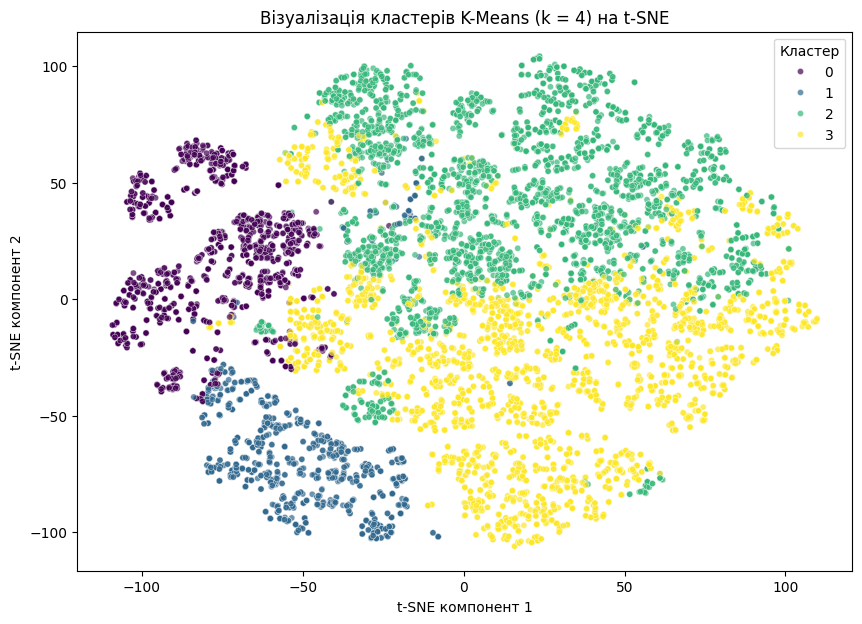

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Кластеризація з оптимальною кількістю кластерів
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

# Візуалізація кластерів на t-SNE проекції
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=clusters,
    palette="viridis",
    s=20,
    alpha=0.7
)

plt.title("Візуалізація кластерів K-Means (k = 4) на t-SNE")
plt.xlabel("t-SNE компонент 1")
plt.ylabel("t-SNE компонент 2")
plt.legend(title="Кластер")
plt.show()

**Аналіз візуалізації результатів кластеризації**

На t-SNE візуалізації результатів алгоритму K-Means при k = 4 спостерігається розподіл об'єктів на чотири кластери, позначені різними кольорами. Кластер 0 переважно розташований у лівій частині графіка, кластер 1 — у нижній лівій частині, кластер 2 — переважно у верхній та центральній частинах, а кластер 3 — у нижній та правій частинах.

Візуалізація демонструє наявність певної структури у даних, однак спостерігається часткове перекриття кластерів. Це свідчить про те, що об'єкти не завжди чітко розділяються за своїми характеристиками.

Отримані результати узгоджуються зі значенням ARI = 0.3035: алгоритм K-Means виявляє часткову відповідність реальним класам, але не забезпечує їх повного відокремлення.